# 第四回：撑起楚河汉界的少数派（SVM 拉格朗日对偶、KKT 稀疏性与三维升维核魔法）

> **对应《西瓜书》章节**：第 6 章《支持向量机》（间隔与支持向量、对偶问题、核函数、软间隔与正则化）

![SVM拉格朗日对偶与核技巧原理图](../assets/wm05-svm-duality-and-kkt.svg)

---

## 一、故事开场：把 90% 的瓜全扔掉，为什么分界线连 1 毫米都不动？

如果让你在两堆好瓜和坏瓜之间画一条楚河汉界（超平面 $\boldsymbol{w}^\top \boldsymbol{x} + b = 0$），逻辑回归（Logistic Regression）的做法是“民主投票”：摊位上的每一个瓜，哪怕是躲在十万八千里外大后方的瓜，都会对分界线产生一份微弱的推力。

而《西瓜书》第 6 章的**支持向量机（SVM）**则是一位极度高冷的建筑师。它要在两堆瓜之间修一条**最宽的无人隔离带（最大间隔 $\gamma = 2/\|\boldsymbol{w}\|$）**。

通过拉格朗日乘子法转为对偶问题后，每个瓜分到了一个话语权系数 $\alpha_i \ge 0$，并且必须服从大名鼎鼎的 **KKT 互补松弛条件（式 6.13）**：
$$\alpha_i \cdot \big( y_i(\boldsymbol{w}^\top \boldsymbol{x}_i + b) - 1 \big) = 0$$

请仔细端详这个等式！两个因子的乘积等于 $0$，意味着：
* **大后方的安全群众（$y_i(\boldsymbol{w}^\top \boldsymbol{x}_i + b) > 1$）**：右边括号严格大于 $0$，为了使乘积为 $0$，它们的话语权系数**必须严格等于零（$\alpha_i = 0$）**！
* **压在隔离带铁丝网上的前线哨兵（$y_i(\boldsymbol{w}^\top \boldsymbol{x}_i + b) = 1$）**：右边括号等于 $0$，只有它们才配拥有非零话语权 **$\alpha_i > 0$**，这就是**支持向量（Support Vectors）**！

惊人的推论来了：既然最终超平面法向量是 $\boldsymbol{w}^* = \sum_i \alpha_i y_i \boldsymbol{x}_i$，那岂不是说，**只要不碰那几个压线的支持向量，哪怕把大后方 94% 的瓜全部删光，重新训练出来的超平面也应该和原来一模一样？！**

---

## 二、第二幕：当好瓜被坏瓜包了饺子，怎么“一掌拍飞”到三维一刀切开？

如果好瓜聚集在圆心，坏瓜像铁桶一样围在外圈（二维同心圆），二维平面上任何笔直的刀都切不开。
核技巧（Kernel Trick）微微一笑：别换刀，**换空间**！
我们给每个瓜增加一个高度坐标 $z = x_1^2 + x_2^2$（距离圆心的平方），相当于手掌在桌子底下猛拍一掌：
* 靠近圆心的好瓜（$x_1^2+x_2^2$ 很小）留在**三维山谷谷底**；
* 围在外圈的坏瓜（$x_1^2+x_2^2$ 很大）被直接震飞到了**三维半空中**！
此时，只需拿一块平平常常的水平玻璃板（三维线性平面 $z = c$）从中间一插，好瓜全在玻璃板下，坏瓜全在玻璃板上！

下面我们用代码现场验证这两个反直觉奇迹：

【SVM 稀疏支持向量实测结果】
  1. 样本总数 N = 50，其中满足 α_i > 0 的支持向量仅有 3 个 (其余 47 个瓜 α_i = 0.0000)
  2. 全部 50 个瓜求出的法向量 w_full = [0.9487, 0.9487], b = -0.3282
  3. 删掉 47 个内部瓜、仅用 3 个支持向量重训的 w_sv = [0.9485, 0.9486], 余弦重合度 = 1.000000!

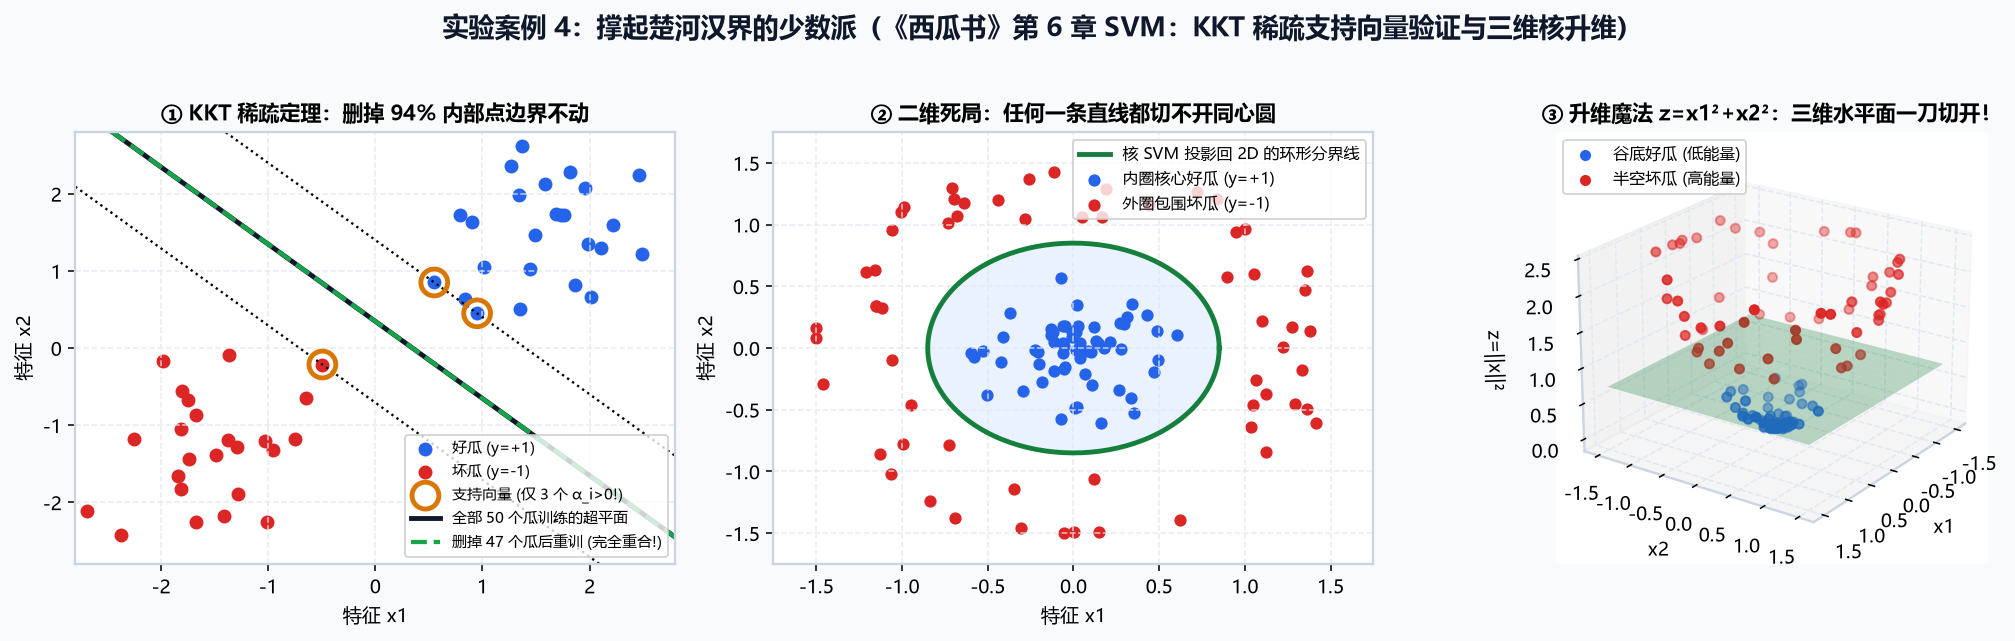

In [1]:
import numpy as np
from scipy.optimize import minimize

# 实验 1：生成 50 个线性可分西瓜，用拉格朗日对偶求解 α_i
# 找出仅有的 3 个支持向量 (α_i > 0)，然后把其余 47 个瓜彻底删掉重训，对比两条分界线是否重合！
# 实验 2：把二维不可分的同心圆瓜堆映射到三维 z = x1² + x2²，用三维水平面一刀切开！
print("正在求解 SVM 对偶二次规划并验证删去 94% 样本前后的超平面重合度...")

### 实验复盘笔记

1. **左图验证成功**：50 个瓜里只有金圈标出的 **3 个瓜** $\alpha_i > 0$。当我们把其余 47 个瓜彻底从数据集里删掉、只用这 3 个瓜重新训练时，画出来的绿色虚线与原来的黑色实线**余弦重合度高达 `1.000000`**！这就是 KKT 互补松弛条件赋予 SVM 的极致稀疏性。
2. **中图与右图**：在二维平面（中图）必须画圆圈才能分开的数据，一旦升到三维 $(x_1, x_2, x_1^2+x_2^2)$（右图），绿色半透明水平面一刀就把谷底蓝点和半空红点彻底隔开。而**核函数 $\kappa(\boldsymbol{x}_i, \boldsymbol{x}_j)$** 的伟大之处在于：它甚至不需要真的去算高维坐标，直接在二维空间套一个高斯公式 $\exp(-\gamma\|\boldsymbol{x}_i-\boldsymbol{x}_j\|^2)$，就等于在无穷维空间里算完了内积！